# What the delineation data looks like

Summary of `DATA/DELINEATION_CLEAN/delineations.csv`, the table written by `build_clean_data.py`
(and extended by `fix_problems.py`). If they exist, it also uses `RESULTS/build_clean_data_report.csv`
(what the cleaning did to the raw files) and the `<problem>_flag` / `_fix` columns of `fix_problems.py`.

Run the pipeline first (`build_clean_data.py`, optionally `fix_problems.py`), then *Run All*.
Nothing is written: this notebook only reads.

In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

# project root = first folder upwards that contains DATA/ (works from ANALYSIS/ or the root)
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "DATA").is_dir())
TABLE = ROOT / "DATA" / "DELINEATION_CLEAN" / "delineations.csv"
REPORT = ROOT / "RESULTS" / "build_clean_data_report.csv"

# chart style: light surface, recessive grid and axes, one validated palette
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"   # categorical slots 1-3 (fixed order)
TEXT, TEXT_2, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "figure.dpi": 110,
    "axes.edgecolor": GRID, "axes.labelcolor": TEXT_2, "xtick.color": TEXT_2, "ytick.color": TEXT_2,
    "text.color": TEXT, "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "axes.grid.axis": "y",
    "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True, "legend.frameon": False,
})


def bars(ax, labels, values, color=BLUE, label_values=True):
    """Thin bars with a 2px gap and value labels in text colour."""
    b = ax.bar([str(x) for x in labels], values, color=color, width=0.7, edgecolor="#fcfcfb", linewidth=2)
    if label_values:
        ax.bar_label(b, padding=2, color=TEXT_2, fontsize=9)
    return b

In [3]:
df = pd.read_csv(TABLE, index_col="index", dtype={"delineationID": str, "raterID": str}, keep_default_na=False)
df["scan"] = df.scantype + "_" + df.delineationID + "_" + df.session.astype(str)
df["subject"] = df.scantype + "_" + df.delineationID
df["group"] = df.raterID.str.split("_").str[0].astype(int)
df["type"] = df.scantype.map({"C": "control (C)", "G": "glaucoma (G)"})
df["file_present"] = [(ROOT / f).exists() for f in df.filepath]   # False = deleted by fix_problems.py
problems = [c.removesuffix("_flag") for c in df.columns if c.endswith("_flag")]

print(f"{len(df)} rows in {TABLE.relative_to(ROOT)}; {(~df.file_present).sum()} files deleted by fix_problems.py")
print("problem columns:", ", ".join(problems) or "none (fix_problems.py not run)")
present = df[df.file_present]
display(df.head())

408 rows in DATA/DELINEATION_CLEAN/delineations.csv; 23 files deleted by fix_problems.py
problem columns: nuclei


,filepath,scantype,delineationID,session,raterID,nuclei_flag,nuclei_fix,scan,subject,group,type,file_present
index,,,,,,,,,,,,
0,DATA/DELINEATION_CLEAN/C_001_1/C_001_1_1_1.nii.gz,C,001,1,1_1,True,deleted: missing 1 2 3 6 7 8 9,C_001_1,C_001,1,control (C),False
1,DATA/DELINEATION_CLEAN/C_001_1/C_001_1_1_2.nii.gz,C,001,1,1_2,False,,C_001_1,C_001,1,control (C),True
2,DATA/DELINEATION_CLEAN/C_001_1/C_001_1_1_3.nii.gz,C,001,1,1_3,False,,C_001_1,C_001,1,control (C),True
3,DATA/DELINEATION_CLEAN/C_001_2/C_001_2_1_1.nii.gz,C,001,2,1_1,False,,C_001_2,C_001,1,control (C),True
4,DATA/DELINEATION_CLEAN/C_001_2/C_001_2_7_1.nii.gz,C,001,2,7_1,False,,C_001_2,C_001,7,control (C),True


## Overview

,count
delineations,385
scans (subject + session),109
subjects,66
raters,79
rater groups,16


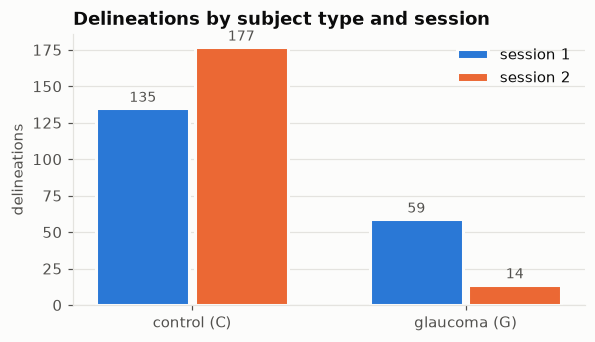

In [4]:
overview = pd.DataFrame({
    "count": [len(present), present.scan.nunique(), present.subject.nunique(),
              present.raterID.nunique(), present.group.nunique()],
}, index=["delineations", "scans (subject + session)", "subjects", "raters", "rater groups"])
display(overview)

fig, ax = plt.subplots(figsize=(6, 3.2))
by = present.groupby(["type", "session"]).size().unstack("session", fill_value=0)
x = range(len(by))
for k, (session, color) in enumerate(zip(by.columns, (BLUE, ORANGE))):
    b = ax.bar([i + (k - 0.5) * 0.36 for i in x], by[session], width=0.34, color=color,
               edgecolor="#fcfcfb", linewidth=2, label=f"session {session}")
    ax.bar_label(b, padding=2, color=TEXT_2, fontsize=9)
ax.set_xticks(list(x), by.index)
ax.set_title("Delineations by subject type and session")
ax.set_ylabel("delineations")
ax.legend(loc="upper right")
plt.show()

## Raters per scan

STAPLE (`staple.py`) only uses scans with **3 or more** raters; scans to the left of the dashed line are skipped.

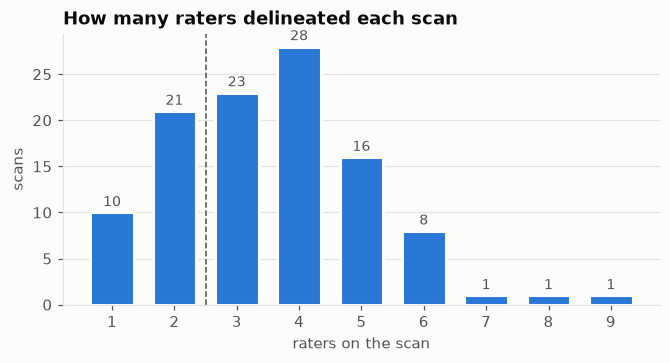

78 of 109 scans have 3 or more raters (used by STAPLE)


In [5]:
per_scan = present.groupby("scan").size()
dist = per_scan.value_counts().sort_index()
fig, ax = plt.subplots(figsize=(7, 3.2))
bars(ax, dist.index, dist.values)
ax.axvline(dist.index.get_loc(3) - 0.5 if 3 in dist.index else 1.5, color=TEXT_2, linestyle="--", linewidth=1)
ax.set_title("How many raters delineated each scan")
ax.set_xlabel("raters on the scan")
ax.set_ylabel("scans")
plt.show()
print(f"{(per_scan >= 3).sum()} of {len(per_scan)} scans have 3 or more raters (used by STAPLE)")

## Sessions per subject

session,both sessions,session 1 only,session 2 only
type,,,
control (C),37,10,3
glaucoma (G),6,10,0


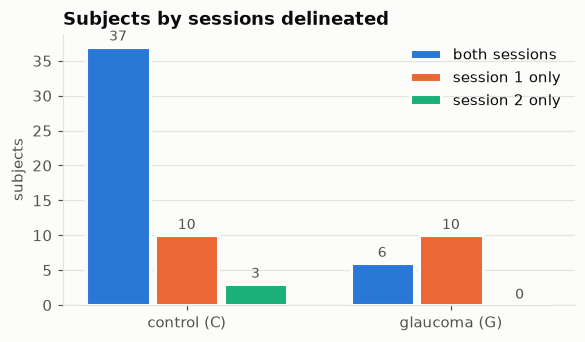

In [6]:
sessions = present.groupby(["type", "subject"]).session.agg(lambda s: tuple(sorted(set(s))))
kind = sessions.map({(1,): "session 1 only", (2,): "session 2 only", (1, 2): "both sessions"})
table = kind.groupby(level="type").value_counts().unstack(fill_value=0)
table = table[[c for c in ("both sessions", "session 1 only", "session 2 only") if c in table]]
display(table)

fig, ax = plt.subplots(figsize=(6, 3.2))
x = range(len(table))
for k, (col, color) in enumerate(zip(table.columns, (BLUE, ORANGE, AQUA))):
    b = ax.bar([i + (k - 1) * 0.26 for i in x], table[col], width=0.24, color=color,
               edgecolor="#fcfcfb", linewidth=2, label=col)
    ax.bar_label(b, padding=2, color=TEXT_2, fontsize=9)
ax.set_xticks(list(x), table.index)
ax.set_title("Subjects by sessions delineated")
ax.set_ylabel("subjects")
ax.legend(loc="upper right")
plt.show()

## Raters and groups

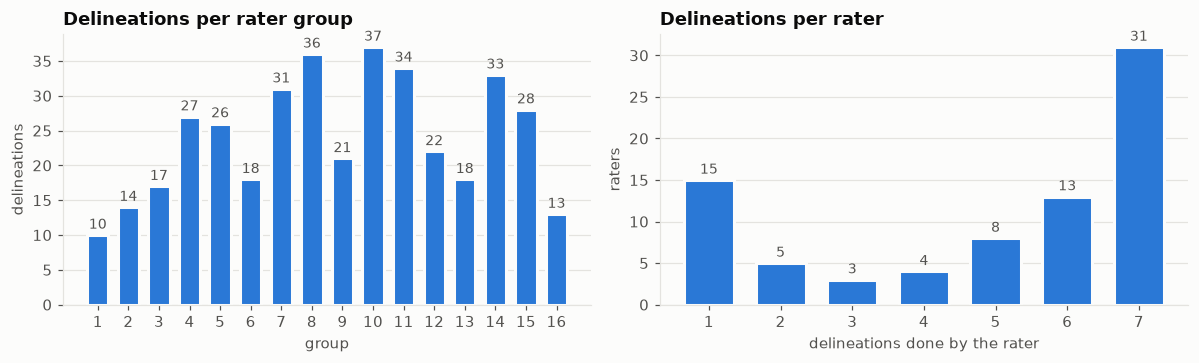

Raters with the most delineations:


,delineations
raterID,
10_3,7
10_5,7
10_4,7
10_7,7
11_7,7
12_1,7
11_4,7
12_2,7
11_6,7


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
per_group = present.groupby("group").size()
bars(axes[0], per_group.index, per_group.values)
axes[0].set_title("Delineations per rater group")
axes[0].set_xlabel("group")
axes[0].set_ylabel("delineations")

per_rater = present.groupby("raterID").size()
dist = per_rater.value_counts().sort_index()
bars(axes[1], dist.index, dist.values)
axes[1].set_title("Delineations per rater")
axes[1].set_xlabel("delineations done by the rater")
axes[1].set_ylabel("raters")
plt.tight_layout()
plt.show()

print("Raters with the most delineations:")
display(per_rater.sort_values(ascending=False).head(10).rename("delineations").to_frame())

## Problems flagged by `fix_problems.py`

One bar per problem that has been run (its `<problem>_flag` column exists). Rows whose file was deleted
by a fix are counted here (the flag explains why they were deleted).

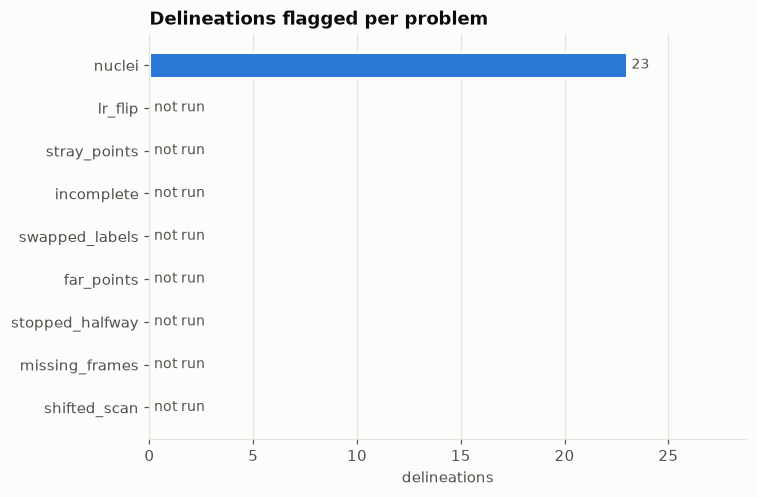

nuclei: what was found / done


,delineations
nuclei_fix,
deleted: missing 8; extra 10,2
deleted: missing 7 8,2
deleted: extra 10,2
deleted: missing 9,2
deleted: missing 1 2 3 6 7 8 9,1
deleted: extra 11 12,1
deleted: missing 7,1
deleted: missing 7; extra 12 13,1
deleted: missing 1 7; extra 10 11,1


In [8]:
import sys
sys.path.insert(0, str(ROOT / "ANALYSIS"))
from fix_problems import PROBLEMS  # every problem, in the order of the instructions

names = list(PROBLEMS)[::-1]  # first problem at the top
flagged = [(df[f"{p}_flag"].astype(str) == "True").sum() if p in problems else 0 for p in names]
fig, ax = plt.subplots(figsize=(7, 0.42 * len(names) + 1))
b = ax.barh(names, flagged, color=BLUE, height=0.6, edgecolor="#fcfcfb", linewidth=2)
ax.bar_label(b, labels=[str(n) if p in problems else "not run" for p, n in zip(names, flagged)],
             padding=3, color=TEXT_2, fontsize=9)
ax.set_xlim(0, max(max(flagged), 1) * 1.25)
ax.grid(axis="y", visible=False)
ax.grid(axis="x", visible=True)
ax.set_title("Delineations flagged per problem")
ax.set_xlabel("delineations")
plt.show()

for p in problems:
    fixes = df.loc[df[f"{p}_flag"].astype(str) == "True", f"{p}_fix"]
    if len(fixes):
        print(f"{p}: what was found / done")
        display(fixes.value_counts().rename("delineations").to_frame())

## What the cleaning did to the raw files

From `RESULTS/build_clean_data_report.csv`: every raw file that was not copied unchanged into `DELINEATION_CLEAN`.

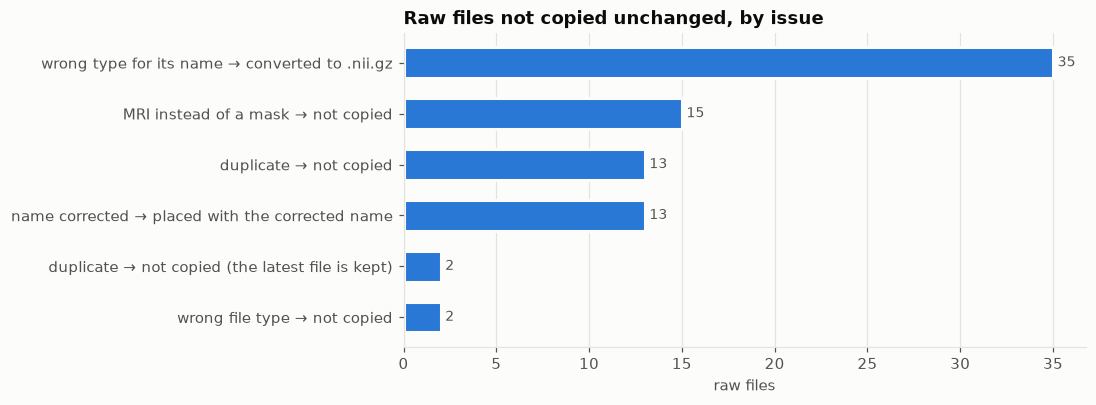

In [9]:
if not REPORT.exists():
    print(f"{REPORT.relative_to(ROOT)} not found: run python ANALYSIS/build_clean_data.py first.")
else:
    report = pd.read_csv(REPORT, keep_default_na=False)
    report["what"] = report.issue.str.replace(r"\s*[:(].*", "", regex=True)
    counts = report.groupby(["action", "what"]).size().sort_values()
    fig, ax = plt.subplots(figsize=(8, 0.45 * len(counts) + 1))
    labels = [f"{what} → {action}" for action, what in counts.index]
    b = ax.barh(labels, counts.values, color=BLUE, height=0.6, edgecolor="#fcfcfb", linewidth=2)
    ax.bar_label(b, padding=3, color=TEXT_2, fontsize=9)
    ax.grid(axis="y", visible=False)
    ax.grid(axis="x", visible=True)
    ax.set_title("Raw files not copied unchanged, by issue")
    ax.set_xlabel("raw files")
    plt.show()